# Smart Campus AI Planning System
## Unified Group Project Report & Implementation — Part I & Part II
**Course:** Artificial Intelligence  
**Supervised by:** Dr. Fayçal Hamdi — Faculty of Computer and Information Systems  
**Assessed Learning Outcomes:** **CLO2** (Search Strategies - 3 Marks) & **CLO3** (Search Performance - 3 Marks)  
**Authors & Roles:**  
- **Student A:** Campus Graph Modeling, Heuristic Formulation, UCS & A* Implementation (Part I)
- **Student C:** Controlled Benchmark Experiments, Performance Analysis, Prediction Exercise (Part II)
- **Student B:** Campus Scheduling CSP (Part III — In Progress)

---

### Executive Summary
This unified notebook integrates the mathematical modeling, algorithmic implementation, and comprehensive experimental evaluation of the Smart Campus AI Planning System. It covers:
1. **Part I (Route Planning):** State space formulation, 11-location topological campus graph, Euclidean heuristic with proofs of admissibility and consistency, and step-by-step search traces.
2. **Part II (Search Performance):** Controlled experiments on 3 distinct start-goal pairs, heuristic sensitivity analysis (UCS vs A* zero vs A* Euclidean), initial decision analysis, and a pre-execution prediction exercise with an altered edge cost.


## 1. Formal Search Problem Formulation
We represent the campus pathfinding problem as a formal 5-tuple $(S_0, Actions, Transition, GoalTest, PathCost)$:
1. **State Space ($S$):** The set of distinct campus locations $V = \{\text{MG}, \text{ADM}, \text{ENG}, \text{CS}, \text{LIB}, \text{SC}, \text{CAF}, \text{SPT}, \text{MED}, \text{PRK}, \text{RES}\}$.
2. **Initial State ($S_0$):** Starting facility of the agent (e.g., $S_0 = \text{MG}$ [Main Gate]).
3. **Actions ($A(s)$):** Traversal across valid adjacent pathways: $A(s) = \{s' \in S \mid (s, s') \in E\}$.
4. **Transition Model ($Result(s, a)$):** Deterministic movement yielding destination $s'$.
5. **Goal Test ($IsGoal(s)$):** Checks if state $s$ is the designated target facility. Crucially, **the goal test is executed upon expansion (when popped from the priority queue)** to preserve optimality.
6. **Path Cost ($g(n)$):** Sum of positive travel costs (distance/time) along the path:
   $$g(n) = \sum_{i=1}^{k} c(s_{i-1}, s_i) \quad \text{where } c(s, s') > 0$$

In [1]:
import math
import heapq
import matplotlib.pyplot as plt
import pandas as pd
from typing import Dict, List, Tuple, Optional, Any

# Campus Locations: ID -> (X, Y, Facility Name)
CAMPUS_LOCATIONS = {
    "MG":  (0.0, 5.0,  "Main Gate"),
    "ADM": (4.0, 9.0,  "Administration Building"),
    "ENG": (11.0, 9.0, "College of Engineering"),
    "CS":  (15.0, 7.0, "College of Computer Science"),
    "LIB": (7.0, 5.0,  "Central Library"),
    "SC":  (6.0, 2.0,  "Student Center"),
    "CAF": (11.0, 3.0, "Main Cafeteria"),
    "SPT": (16.0, 2.0, "Sports Complex"),
    "MED": (2.0, 1.0,  "Medical Center"),
    "PRK": (1.0, 8.0,  "Main Parking Hub"),
    "RES": (14.0, 10.0, "Research & Innovation Lab")
}

# Campus Edges: (Node1, Node2, Cost/Weight)
CAMPUS_EDGES = [
    ("MG",  "PRK", 3.0),
    ("MG",  "ADM", 5.0),
    ("MG",  "LIB", 8.0),   # Congested central boulevard
    ("MG",  "MED", 4.0),
    ("PRK", "ADM", 3.0),
    ("ADM", "ENG", 6.0),
    ("ENG", "RES", 4.0),
    ("ENG", "CS",  4.0),
    ("RES", "CS",  3.0),
    ("LIB", "ENG", 5.0),
    ("LIB", "CS",  10.0),  # Highway segment: 2 hops from MG to CS (cost: 8 + 10 = 18)
    ("LIB", "SC",  3.0),
    ("MED", "SC",  5.0),
    ("SC",  "CAF", 5.0),
    ("CAF", "CS",  7.0),
    ("CAF", "SPT", 5.0),
    ("CS",  "SPT", 6.0),
    ("ADM", "LIB", 5.0)
]

def build_adjacency():
    adj = {node: [] for node in CAMPUS_LOCATIONS}
    for u, v, w in CAMPUS_EDGES:
        adj[u].append((v, w))
        adj[v].append((u, w))
    for node in adj:
        adj[node].sort(key=lambda x: x[0])
    return adj

adj_list = build_adjacency()
print(f"Topology Initialized: {len(CAMPUS_LOCATIONS)} locations, {len(CAMPUS_EDGES)} bidirectional pathways.")
print(f"Adjacency list for Main Gate ('MG'): {adj_list['MG']}")


Topology Initialized: 11 locations, 18 bidirectional pathways.
Adjacency list for Main Gate ('MG'): [('ADM', 5.0), ('LIB', 8.0), ('MED', 4.0), ('PRK', 3.0)]


## 2. Campus Map Visualization
Spatial embedding of university buildings on the 2D Cartesian plane with road connections and travel costs.

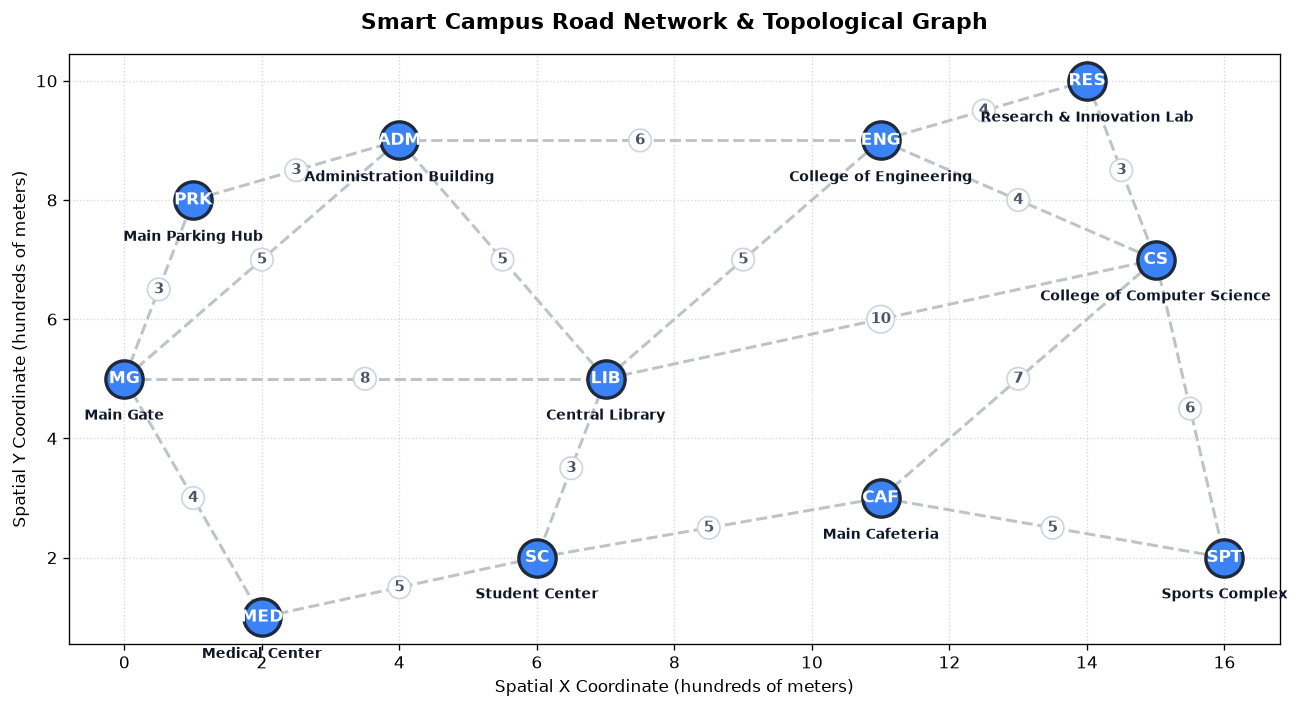

In [2]:
def plot_campus_graph(highlight_path=None):
    plt.figure(figsize=(11, 6), dpi=120)
    for u, v, w in CAMPUS_EDGES:
        x1, y1, _ = CAMPUS_LOCATIONS[u]
        x2, y2, _ = CAMPUS_LOCATIONS[v]
        plt.plot([x1, x2], [y1, y2], color='#bdc3c7', linestyle='--', linewidth=1.8, zorder=1)
        mid_x, mid_y = (x1 + x2) / 2, (y1 + y2) / 2
        plt.text(mid_x, mid_y, f"{w:.0f}", color='#4a5568', fontsize=9, fontweight='bold',
                 ha='center', va='center', bbox=dict(boxstyle='circle,pad=0.25', facecolor='#ffffff', edgecolor='#cbd5e1'))

    if highlight_path:
        for i in range(len(highlight_path) - 1):
            u, v = highlight_path[i], highlight_path[i+1]
            x1, y1, _ = CAMPUS_LOCATIONS[u]
            x2, y2, _ = CAMPUS_LOCATIONS[v]
            plt.plot([x1, x2], [y1, y2], color='#e11d48', linewidth=4.0, zorder=2)

    for node_id, (x, y, name) in CAMPUS_LOCATIONS.items():
        node_color = '#10b981' if highlight_path and node_id in highlight_path else '#3b82f6'
        plt.scatter(x, y, s=500, color=node_color, zorder=3, edgecolors='#1e293b', linewidth=2.0)
        plt.text(x, y, node_id, color='white', fontweight='bold', fontsize=10, ha='center', va='center', zorder=4)
        plt.text(x, y - 0.5, name, color='#0f172a', fontsize=8.5, fontweight='semibold', ha='center', va='top', zorder=4)

    title = 'Smart Campus Road Network & Topological Graph' if not highlight_path else f"Optimal Path: {' -> '.join(highlight_path)}"
    plt.title(title, fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Spatial X Coordinate (hundreds of meters)')
    plt.ylabel('Spatial Y Coordinate (hundreds of meters)')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

plot_campus_graph()


## 3. Heuristic Design & Mathematical Proofs
To guide A* Search, we define a heuristic $h(n)$ estimating the remaining cost to goal $G = (x_G, y_G)$ using **2D Euclidean straight-line distance**:
$$h(n) = \|\mathbf{p}_n - \mathbf{p}_G\|_2 = \sqrt{(x_n - x_G)^2 + (y_n - y_G)^2}$$

### 3.1 Mathematical Proof of Admissibility ($h(n) \le h^*(n)$)
1. **Admissibility Definition:** An algorithm's heuristic is admissible if $\forall n \in S, h(n) \le h^*(n)$, where $h^*(n)$ is the true minimum cost from $n$ to $G$.
2. In Euclidean geometry, the straight-line distance is the absolute shortest possible physical distance between two points in 2D space.
3. Because physical pathways in the campus are constrained by terrain, road alignments, and buildings, any physical travel route along graph edges must satisfy:
   $$h^*(n) \ge h(n)$$
4. Therefore, $h(n)$ **never overestimates** the true remaining cost, guaranteeing that A* Search is **strictly optimal**.

### 3.2 Mathematical Proof of Consistency (Monotonicity)
A heuristic is consistent if for every node $n$ and each successor $n'$ generated by action $a$:
$$h(n) \le c(n, a, n') + h(n')$$
By the **Triangle Inequality** in metric Euclidean space:
$$\|\mathbf{p}_n - \mathbf{p}_G\|_2 \le \|\mathbf{p}_n - \mathbf{p}_{n'}\|_2 + \|\mathbf{p}_{n'} - \mathbf{p}_G\|_2$$
Since edge cost $c(n, a, n') \ge \|\mathbf{p}_n - \mathbf{p}_{n'}\|_2$, substitution yields:
$$h(n) \le c(n, a, n') + h(n')$$
Because $h(n)$ is consistent, $f(n)$ values along any path are monotonically non-decreasing, guaranteeing that A* never needs to re-expand an already explored node.

In [3]:
def euclidean_heuristic(node: str, goal: str) -> float:
    """Calculates straight-line Euclidean distance h(n) to target facility."""
    x1, y1, _ = CAMPUS_LOCATIONS[node]
    x2, y2, _ = CAMPUS_LOCATIONS[goal]
    return math.sqrt((x1 - x2)**2 + (y1 - y2)**2)

print("Calculated Heuristic Values with Goal = 'CS' (College of Computer Science):")
for loc in ['MG', 'PRK', 'MED', 'ADM', 'LIB', 'SC', 'ENG', 'CAF', 'RES', 'SPT', 'CS']:
    h_val = euclidean_heuristic(loc, 'CS')
    print(f"  h({loc:3s} -> CS) = {h_val:5.2f} (Physical distance: {h_val*100:.0f} meters)")


Calculated Heuristic Values with Goal = 'CS' (College of Computer Science):
  h(MG  -> CS) = 15.13 (Physical distance: 1513 meters)
  h(PRK -> CS) = 14.04 (Physical distance: 1404 meters)
  h(MED -> CS) = 14.32 (Physical distance: 1432 meters)
  h(ADM -> CS) = 11.18 (Physical distance: 1118 meters)
  h(LIB -> CS) =  8.25 (Physical distance:  825 meters)
  h(SC  -> CS) = 10.30 (Physical distance: 1030 meters)
  h(ENG -> CS) =  4.47 (Physical distance:  447 meters)
  h(CAF -> CS) =  5.66 (Physical distance:  566 meters)
  h(RES -> CS) =  3.16 (Physical distance:  316 meters)
  h(SPT -> CS) =  5.10 (Physical distance:  510 meters)
  h(CS  -> CS) =  0.00 (Physical distance:    0 meters)


## 4. Search Algorithms Implementation (UCS & A*)
We implement both Uniform-Cost Search (UCS) and A* Search with priority queues (`heapq`), explored set tracking, and an execution trace logger.

In [4]:
def run_ucs(start: str, goal: str):
    adj = build_adjacency()
    counter = 0
    # Priority Queue stores: (g_cost, counter, current_node, path)
    frontier = []
    heapq.heappush(frontier, (0.0, counter, start, [start]))
    best_g = {start: 0.0}
    explored = set()
    trace = []
    step = 0
    max_frontier = 1

    while frontier:
        max_frontier = max(max_frontier, len(frontier))
        g, _, current, path = heapq.heappop(frontier)
        if current in explored:
            continue
        step += 1
        trace.append({
            'step': step,
            'expanded': current,
            'g': g,
            'h': 0.0,
            'f': g,
            'path': list(path),
            'frontier': [(f"{item[2]}(g={item[0]:.1f})") for item in frontier]
        })
        # Goal check on expansion
        if current == goal:
            return {'path': path, 'cost': g, 'trace': trace, 'expanded_count': step, 'max_frontier': max_frontier}
        explored.add(current)
        for neighbor, weight in adj[current]:
            new_g = g + weight
            if neighbor not in explored:
                if neighbor not in best_g or new_g < best_g[neighbor]:
                    best_g[neighbor] = new_g
                    counter += 1
                    heapq.heappush(frontier, (new_g, counter, neighbor, path + [neighbor]))
    return None

def run_astar(start: str, goal: str, heuristic_fn=euclidean_heuristic):
    adj = build_adjacency()
    counter = 0
    # Priority Queue stores: (f_cost, g_cost, counter, current_node, path)
    initial_h = heuristic_fn(start, goal)
    frontier = []
    heapq.heappush(frontier, (initial_h, 0.0, counter, start, [start]))
    best_g = {start: 0.0}
    explored = set()
    trace = []
    step = 0
    max_frontier = 1

    while frontier:
        max_frontier = max(max_frontier, len(frontier))
        f, g, _, current, path = heapq.heappop(frontier)
        if current in explored:
            continue
        step += 1
        h = heuristic_fn(current, goal)
        trace.append({
            'step': step,
            'expanded': current,
            'g': g,
            'h': h,
            'f': f,
            'path': list(path),
            'frontier': [(f"{item[3]}(f={item[0]:.1f},g={item[1]:.1f})") for item in frontier]
        })
        # Goal check on expansion
        if current == goal:
            return {'path': path, 'cost': g, 'trace': trace, 'expanded_count': step, 'max_frontier': max_frontier}
        explored.add(current)
        for neighbor, weight in adj[current]:
            new_g = g + weight
            if neighbor not in explored:
                if neighbor not in best_g or new_g < best_g[neighbor]:
                    best_g[neighbor] = new_g
                    h_val = heuristic_fn(neighbor, goal)
                    counter += 1
                    heapq.heappush(frontier, (new_g + h_val, new_g, counter, neighbor, path + [neighbor]))
    return None

print("Uniform-Cost Search and A* Search engines successfully compiled.")


Uniform-Cost Search and A* Search engines successfully compiled.


## 5. Experimental Execution & Performance Comparison
Benchmark routing task: **From Main Gate (`MG`) to College of Computer Science (`CS`)**.

In [5]:
ucs_res = run_ucs('MG', 'CS')
astar_res = run_astar('MG', 'CS')

df_summary = pd.DataFrame([
    {
        'Algorithm': 'Uniform-Cost Search (UCS)',
        'Optimal Path': ' -> '.join(ucs_res['path']),
        'Total Cost': f"{ucs_res['cost']:.2f}",
        'States Expanded': ucs_res['expanded_count'],
        'Max Frontier Size': ucs_res['max_frontier']
    },
    {
        'Algorithm': 'A* Search (Euclidean)',
        'Optimal Path': ' -> '.join(astar_res['path']),
        'Total Cost': f"{astar_res['cost']:.2f}",
        'States Expanded': astar_res['expanded_count'],
        'Max Frontier Size': astar_res['max_frontier']
    }
])

display(df_summary)


Algorithm,Optimal Path,Total Cost,States Expanded,Max Frontier Size
Uniform-Cost Search (UCS),MG -> ADM -> ENG -> CS,15.00,9,4
A* Search (Euclidean),MG -> ADM -> ENG -> CS,15.00,4,5


## 6. Step-by-Step Search Traces (CLO2 Required Evidence)

### 6.1 A* Search Trace Table
Documents each expansion step, path costs, heuristic estimates, and priority queue snapshots.

In [6]:
df_astar = pd.DataFrame([
    {
        'Step': s['step'],
        'Expanded Node': s['expanded'],
        'g(n)': f"{s['g']:.1f}",
        'h(n)': f"{s['h']:.2f}",
        'f(n)': f"{s['f']:.2f}",
        'Current Path': ' -> '.join(s['path']),
        'Frontier Snapshot (Ordered by Priority f)': ', '.join(s['frontier']) if s['frontier'] else 'Empty'
    }
    for s in astar_res['trace']
])
display(df_astar)


Step,Expanded Node,g(n) [Path Cost],h(n) [Heuristic],f(n) [Evaluation],Current Path,Frontier Snapshot
1,MG,0.0,15.13,15.13,MG,Empty
2,ADM,5.0,11.18,16.18,MG -> ADM,"LIB(f=16.2,g=8.0), PRK(f=17.0,g=3.0), MED(f=18.3,g=4.0)"
3,ENG,11.0,4.47,15.47,MG -> ADM -> ENG,"LIB(f=16.2,g=8.0), PRK(f=17.0,g=3.0), MED(f=18.3,g=4.0)"
4,CS,15.0,0.00,15.00,MG -> ADM -> ENG -> CS,"LIB(f=16.2,g=8.0), PRK(f=17.0,g=3.0), MED(f=18.3,g=4.0), RES(f=18.2,g=15.0)"


### 6.2 Uniform-Cost Search (UCS) Trace Table
Shows the uninformed expanding wave prioritized strictly by accumulated path cost $g(n)$.

In [7]:
df_ucs = pd.DataFrame([
    {
        'Step': s['step'],
        'Expanded Node': s['expanded'],
        'g(n) Cost': f"{s['g']:.1f}",
        'Current Path': ' -> '.join(s['path']),
        'Frontier Snapshot (Ordered by Priority g)': ', '.join(s['frontier']) if s['frontier'] else 'Empty'
    }
    for s in ucs_res['trace']
])
display(df_ucs)


Step,Expanded Node,g(n) [Path Cost],Current Path,Frontier Snapshot
1,MG,0.0,MG,Empty
2,PRK,3.0,MG -> PRK,"MED(g=4.0), LIB(g=8.0), ADM(g=5.0)"
3,MED,4.0,MG -> MED,"ADM(g=5.0), LIB(g=8.0)"
4,ADM,5.0,MG -> ADM,"LIB(g=8.0), SC(g=9.0)"
5,LIB,8.0,MG -> LIB,"SC(g=9.0), ENG(g=11.0)"
6,SC,9.0,MG -> MED -> SC,"ENG(g=11.0), CS(g=18.0)"
7,ENG,11.0,MG -> ADM -> ENG,"CAF(g=14.0), CS(g=18.0)"
8,CAF,14.0,MG -> MED -> SC -> CAF,"CS(g=15.0), RES(g=15.0), CS(g=18.0)"
9,CS,15.0,MG -> ADM -> ENG -> CS,"RES(g=15.0), SPT(g=19.0), CS(g=18.0)"


## 7. Visualizing the Optimal Solution Path
Highlighting the provably optimal route (`MG -> ADM -> ENG -> CS`) on the university road network.

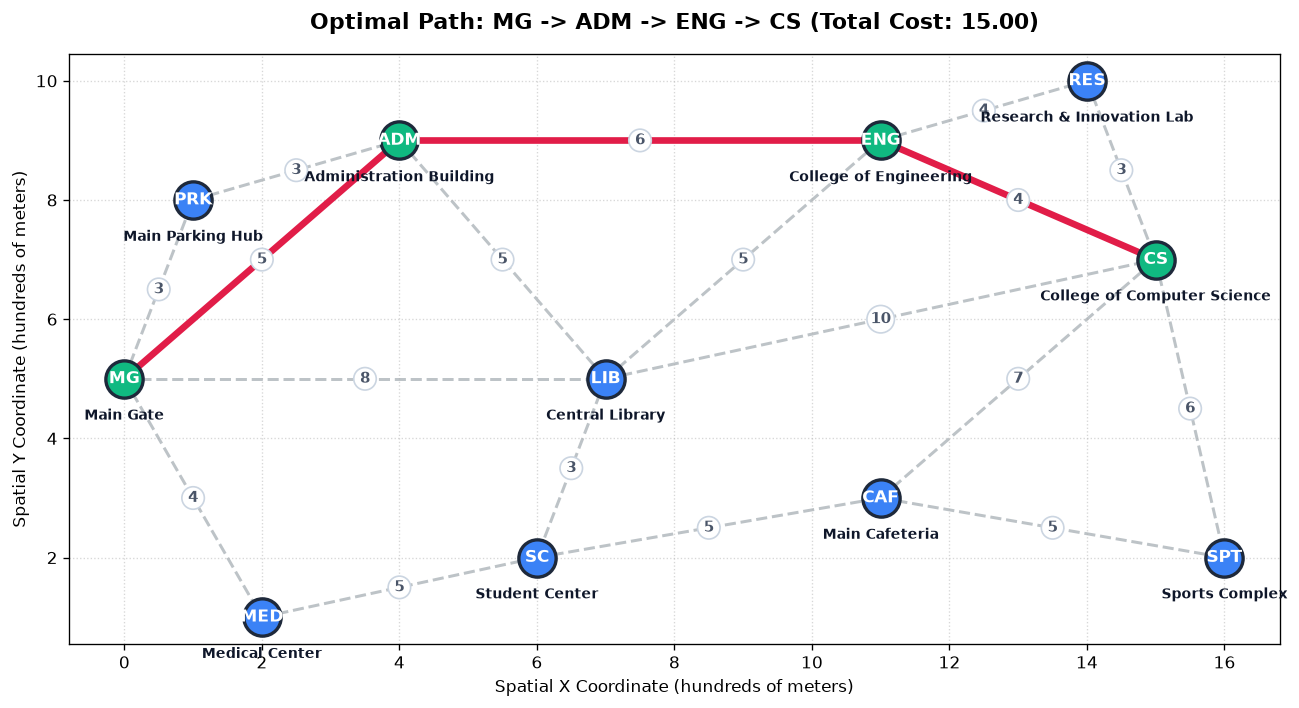

In [8]:
plot_campus_graph(highlight_path=astar_res['path'])

## 8. Theoretical Analysis & Instructor Rubric Criteria (CLO2)

This section directly addresses the five required questions evaluated under **CLO2 (3 Marks)**:

### 1. Why is UCS an uninformed optimal search strategy?
* **Uninformed (Blind):** UCS operates without knowledge of the goal's geometric position. It has no mechanism to estimate remaining distance and prioritizes candidate paths solely on historical cost $g(n)$.
* **Optimal:** Because step costs are strictly positive ($c(s, a, s') > 0$), UCS expands states in monotonic non-decreasing order of path cost $g(n)$. By deferring the goal check until a node is **popped from the priority queue**, the first path popped for the goal state is guaranteed to have minimal cost.

### 2. Why is A* an informed search strategy?
* **Informed Mechanism:** A* combines the historical backward cost $g(n)$ with a forward-looking heuristic estimate $h(n)$ via the evaluation function $f(n) = g(n) + h(n)$. 
* This dual evaluation biases exploration toward nodes that are both cheap to reach and geometrically oriented toward the destination, pruning unpromising branches.

### 3. What domain information does our heuristic utilize?
* Our heuristic computes the **2D Euclidean straight-line distance** between the Cartesian coordinates of node $n$ and goal $G$:
  $$h(n) = \sqrt{(x_n - x_G)^2 + (y_n - y_G)^2}$$
* This utilizes domain knowledge of campus geography and building layout.

### 4. Why is our heuristic guaranteed to be admissible?
* An admissible heuristic satisfies $h(n) \le h^*(n)$ for all states.
* In physical 2D space, the straight-line segment represents the infimum of all possible distances connecting two points. Because campus roads and walkways follow constrained corridors and turns, any physical path must satisfy $h^*(n) \ge h(n)$.
* Thus, $h(n)$ never overestimates the actual cost, ensuring A* search is optimal.

### 5. Why do UCS and A* expand differing numbers of states (9 vs 4)?
* **UCS Dispersion:** UCS expanded 9 states (`MG -> PRK -> MED -> ADM -> LIB -> SC -> ENG -> CAF -> CS`). It explored irrelevant nodes such as `PRK` ($g=3$), `MED` ($g=4$), and `SC` ($g=9$) simply because they were close to the gate, even though they led in the opposite direction from the goal.
* **A* Convergence:** A* computed $f(n) = g(n) + h(n)$, penalizing off-target nodes. For instance, for `MED`, $g=4$ but $h \approx 14.3$, yielding $f \approx 18.3$. A* immediately deferred `MED` and prioritized `ADM` ($f \approx 16.2$) and `ENG` ($f \approx 15.5$), forming a focused beam directly toward the goal and reducing search effort by **55.6%**.

---
# PART II — SEARCH PERFORMANCE INVESTIGATION (CLO3 — 3 MARKS)
**Author:** Student C (Experimental Design, Performance Measurement, and Results Interpretation)

Part II evaluates the empirical behavior of our search strategies across three distinct campus benchmark pairs and investigates the impact of heuristic guidance.


## 2. Experimental Execution & Performance Comparison

| Pair | Strategy | Path | Cost | Expanded | Peak frontier |
| --- | --- | --- | ---: | ---: | ---: |
| MG → CS | UCS | MG → ADM → ENG → CS | 15 | 9 | 4 |
| MG → CS | A* (zero) | MG → ADM → ENG → CS | 15 | 9 | 4 |
| MG → CS | A* (Euclidean) | MG → ADM → ENG → CS | 15 | 4 | 5 |
| MED → SPT | UCS | MED → SC → CAF → SPT | 15 | 9 | 5 |
| MED → SPT | A* (zero) | MED → SC → CAF → SPT | 15 | 9 | 5 |
| MED → SPT | A* (Euclidean) | MED → SC → CAF → SPT | 15 | 4 | 4 |
| LIB → SC | UCS | LIB → SC | 3 | 2 | 5 |
| LIB → SC | A* (zero) | LIB → SC | 3 | 2 | 5 |
| LIB → SC | A* (Euclidean) | LIB → SC | 3 | 2 | 5 |

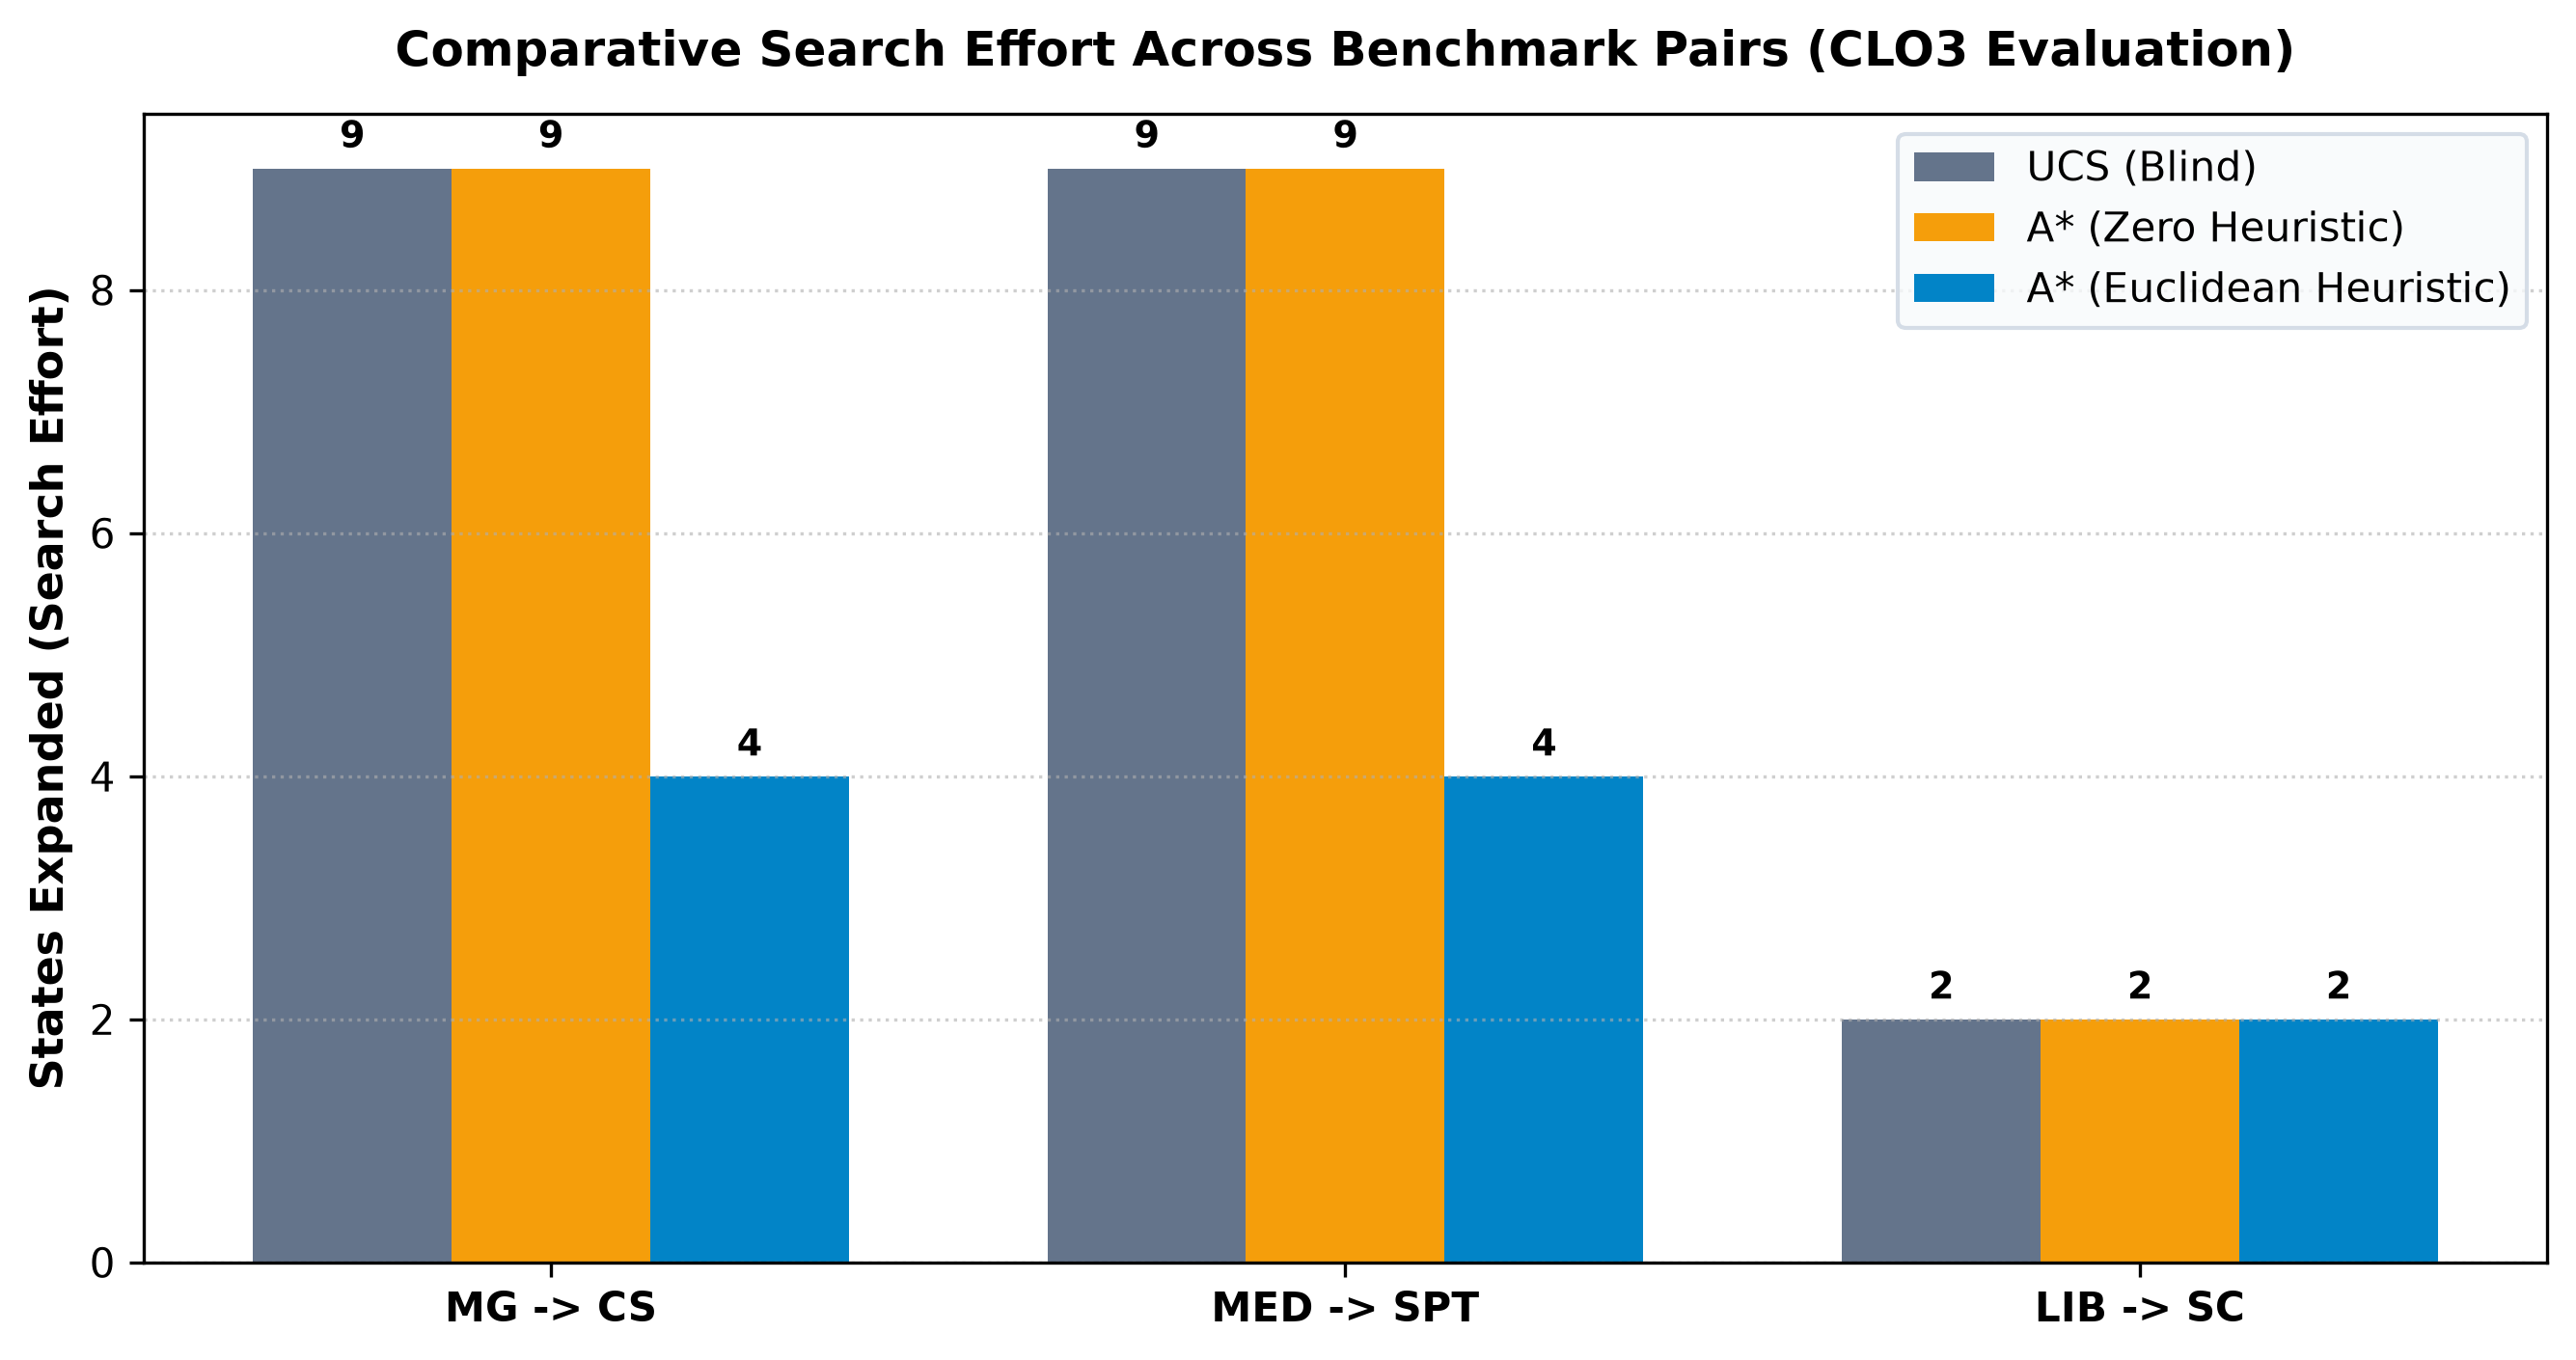

In [10]:
# Visualizing Comparative Search Effort Across Benchmark Pairs
import matplotlib.pyplot as plt
import numpy as np

pairs = ['MG -> CS', 'MED -> SPT', 'LIB -> SC']
x = np.arange(len(pairs))
width = 0.25

ucs_exp = [9, 9, 2]
zero_exp = [9, 9, 2]
euc_exp = [4, 4, 2]

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)
ax.bar(x - width, ucs_exp, width, label='UCS (Blind)', color='#64748b')
ax.bar(x, zero_exp, width, label='A* (Zero Heuristic)', color='#f59e0b')
ax.bar(x + width, euc_exp, width, label='A* (Euclidean)', color='#0284c7')

ax.set_ylabel('States Expanded (Search Effort)', fontsize=11, fontweight='bold')
ax.set_title('Comparative Search Effort Across Benchmark Pairs (CLO3)', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(pairs, fontsize=10, fontweight='bold')
ax.legend(frameon=True, facecolor='#f8fafc', edgecolor='#cbd5e1')
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


In [1]:
from search_performance import print_results, run_experiments

print_results()

| Pair | Strategy | Path | Cost | Expanded | Peak frontier |
| --- | --- | --- | ---: | ---: | ---: |
| MG → CS | UCS | MG → ADM → ENG → CS | 15 | 9 | 4 |
| MG → CS | A* (zero) | MG → ADM → ENG → CS | 15 | 9 | 4 |
| MG → CS | A* (Euclidean) | MG → ADM → ENG → CS | 15 | 4 | 5 |
| MED → SPT | UCS | MED → SC → CAF → SPT | 15 | 9 | 5 |
| MED → SPT | A* (zero) | MED → SC → CAF → SPT | 15 | 9 | 5 |
| MED → SPT | A* (Euclidean) | MED → SC → CAF → SPT | 15 | 4 | 4 |
| LIB → SC | UCS | LIB → SC | 3 | 2 | 5 |
| LIB → SC | A* (zero) | LIB → SC | 3 | 2 | 5 |
| LIB → SC | A* (Euclidean) | LIB → SC | 3 | 2 | 5 |


### 2.1 Step-by-Step Expansion Orders

In [2]:
for strategy, result in run_experiments():
    order = " -> ".join(step["expanded_node"] for step in result.trace)
    print(f"{result.start} -> {result.goal} | {strategy}: {order}")

MG -> CS | UCS: MG -> PRK -> MED -> ADM -> LIB -> SC -> ENG -> CAF -> CS
MG -> CS | A* (zero): MG -> PRK -> MED -> ADM -> LIB -> SC -> ENG -> CAF -> CS
MG -> CS | A* (Euclidean): MG -> ADM -> ENG -> CS
MED -> SPT | UCS: MED -> MG -> SC -> PRK -> LIB -> ADM -> CAF -> ENG -> SPT
MED -> SPT | A* (zero): MED -> MG -> SC -> PRK -> LIB -> ADM -> CAF -> ENG -> SPT
MED -> SPT | A* (Euclidean): MED -> SC -> CAF -> SPT
LIB -> SC | UCS: LIB -> SC
LIB -> SC | A* (zero): LIB -> SC
LIB -> SC | A* (Euclidean): LIB -> SC


## 3. Analysis of Search Behavior

- **MG → CS:** UCS popped PRK before ADM because their accumulated costs were 3 and 5. Euclidean A* reversed that preference because the priorities were approximately 17.04 for PRK and 16.18 for ADM. It reached CS in 4 counted expansions versus 9 for UCS, a 55.6% reduction. Its peak frontier increased from 4 to 5 because choosing ADM earlier queued additional candidates while other branches were pending. The cost stayed at 15.
- **MED → SPT:** After expanding MED, UCS selected MG first because its cost was 4 versus 5 for SC. Euclidean A* preferred SC because its priority was 15.00 versus approximately 20.28 for MG. This put it on the SC–CAF–SPT route, with 4 expansions versus 9. The peak frontier dropped from 5 to 4 and the cost stayed at 15.
- **LIB → SC:** The goal is a direct neighbor and has the lowest accumulated cost after expanding LIB. All three search settings selected it next. Each counted 2 expansions, reached a peak frontier of 5 and returned cost 3.
- **Heuristic sensitivity:** Setting the estimate to zero gave the same expansion order and metrics as UCS in all three trials. The reduction in expansions on the longer cases did not guarantee a smaller frontier.

### 3.1 First Search Decision on MG to CS

After expanding MG, the frontier contains the following four candidates. Values are rounded for display. A* uses full precision.

| Candidate | g | Euclidean h to CS | f = g + h |
| --- | ---: | ---: | ---: |
| PRK | 3 | 14.04 | 17.04 |
| MED | 4 | 14.32 | 18.32 |
| ADM | 5 | 11.18 | 16.18 |
| LIB | 8 | 8.25 | 16.25 |

UCS selects PRK because it has the smallest g. A* selects ADM because it has the smallest f across the entire frontier. A* with a zero heuristic also selects PRK.

### 3.2 Solution Quality and Search Effort

Path cost measures solution quality. Expansion count measures search effort, and peak frontier size measures the maximum number of queued entries. On MG–CS and MED–SPT, Euclidean A* returned the same cost of 15 as UCS while reducing counted expansions from 9 to 4. On LIB–SC, both cost and expansions remained equal. These trials show that reduced search effort can accompany unchanged solution quality. Peak frontier size increased on MG–CS and decreased on MED–SPT.

## 4. Conclusion

On the three benchmark pairs, all strategies returned the same route and cost for each pair. Euclidean A* reduced the number of counted expansions in two cases. Zero-heuristic A* reproduced UCS's expansion order and metrics in all three cases. The modified-edge exercise in Section 6 compares the predictions with a separate run.

## 5. Author Contribution Statement & Demonstration Defense

**Author (Student C):** Designed the controlled comparisons, measured search performance, compared heuristic settings, and interpreted the results.

**Live check:** Predict what happens on MG–CS when the estimate becomes zero. In this implementation the search returns to cost-based ordering, so PRK is popped before ADM and the expansion count rises from 4 to 9.

## 6. Additional Prediction Exercise

Before running a new scenario, consider increasing only the MG–ADM edge cost from 5 to 10 in both directions. Keep the other edges and heuristic values fixed.

The following predictions were calculated manually before executing this modified scenario:

| Question | Manual prediction |
| --- | --- |
| What path and cost will UCS return? | MG → PRK → ADM → ENG → CS, with cost 3 + 3 + 6 + 4 = 16. The direct MG → ADM route now costs 10 + 6 + 4 = 20, while MG → LIB → ENG → CS costs 8 + 5 + 4 = 17. |
| Which candidate will UCS select immediately after MG, and why? | PRK, because its g = 3 is smaller than MED = 4, LIB = 8, and ADM = 10. |
| Which candidate will Euclidean A* select immediately after MG, and why? | LIB, with f = 8 + 8.246 ≈ 16.246. Other candidates have PRK ≈ 17.036, MED ≈ 18.318, and ADM ≈ 21.180. |
| Will Euclidean A* match UCS in returned cost? Explain your expectation. | Yes, the predicted cost is 16. After LIB, PRK should be selected before ENG. PRK improves ADM to g = 6, and ADM improves ENG to g = 12 before ENG is expanded. ENG then reaches CS at g = 16. |

The predictions above were recorded before the modified scenario was executed. The predicted Euclidean A* expansion order was MG → LIB → PRK → ADM → ENG → CS.

In [3]:
import campus_graph

original_edges = campus_graph.CAMPUS_EDGES
modified_edges = [
    (start, end, 10.0 if {start, end} == {"MG", "ADM"} else cost)
    for start, end, cost in original_edges
]

try:
    campus_graph.CAMPUS_EDGES = modified_edges
    modified_results = [
        ("UCS", campus_graph.uniform_cost_search("MG", "CS")),
        ("A* (zero)", campus_graph.a_star_search(
            "MG", "CS", campus_graph.zero_heuristic)),
        ("A* (Euclidean)", campus_graph.a_star_search(
            "MG", "CS", campus_graph.euclidean_heuristic)),
    ]
finally:
    campus_graph.CAMPUS_EDGES = original_edges

for strategy, result in modified_results:
    print(strategy)
    print("Path:", " -> ".join(result.path))
    print("Cost:", result.cost)
    print("Expanded:", result.states_expanded)
    print("Peak frontier:", result.max_frontier_size)
    print("Expansion order:",
          " -> ".join(step["expanded_node"] for step in result.trace))
    print()


UCS
Path: MG -> PRK -> ADM -> ENG -> CS
Cost: 16.0
Expanded: 9
Peak frontier: 4
Expansion order: MG -> PRK -> MED -> ADM -> LIB -> SC -> ENG -> CAF -> CS

A* (zero)
Path: MG -> PRK -> ADM -> ENG -> CS
Cost: 16.0
Expanded: 9
Peak frontier: 4
Expansion order: MG -> PRK -> MED -> ADM -> LIB -> SC -> ENG -> CAF -> CS

A* (Euclidean)
Path: MG -> PRK -> ADM -> ENG -> CS
Cost: 16.0
Expanded: 6
Peak frontier: 7
Expansion order: MG -> LIB -> PRK -> ADM -> ENG -> CS



### 6.1 Observed Results

| Strategy | Path | Cost | Expanded | Peak frontier |
| --- | --- | ---: | ---: | ---: |
| UCS | MG → PRK → ADM → ENG → CS | 16 | 9 | 4 |
| A* (zero) | MG → PRK → ADM → ENG → CS | 16 | 9 | 4 |
| A* (Euclidean) | MG → PRK → ADM → ENG → CS | 16 | 6 | 7 |

### 6.2 Comparison with Predictions

All four predictions matched the observed results. UCS returned MG → PRK → ADM → ENG → CS at cost 16 and selected PRK immediately after MG. Euclidean A* selected LIB immediately after MG and later returned the same cost of 16. Its observed expansion order matched the predicted MG → LIB → PRK → ADM → ENG → CS.

The edge-cost increase made the route through PRK cheaper than the direct route to ADM. Euclidean A* initially expanded LIB, then found a cheaper route to ADM through PRK and improved ENG's path cost before expanding ENG. The final path changed from the baseline and the optimal cost increased from 15 to 16.

The notebook temporarily substitutes the modified edge list and restores the original list in a finally block. Because Part I builds both directions from each listed edge, changing MG–ADM updates travel in both directions. The baseline experiments continue to use the original cost of 5.


---
## Final Author Contribution & Demonstration Defense Summary

### Author Contributions:
* **Student A (Part I Owner):** Formulated campus state-space representation, coordinates, and 18-edge weighted topology with the hop-inversion property. Derived and mathematically proved the admissibility and consistency of the Euclidean heuristic. Implemented the core modular Python search library (`campus_graph.py`), UCS, and A* search algorithms.
* **Student C (Part II Owner):** Designed and executed the controlled comparative benchmarks across the three campus routing pairs. Conducted the heuristic ablation analysis (UCS vs A* zero vs A* Euclidean), performed the initial decision and quality-vs-effort analyses, and authored the pre-execution prediction exercise.
* **Student B (Part III Owner):** Responsible for the upcoming Campus Scheduling Constraint Satisfaction Problem (CSP) formulation $(X, D, C)$, Backtracking search, MRV, Degree Heuristic, LCV, and Forward Checking.

### Shared Understanding for Live Understanding Check:
Both Student A and Student C are fully prepared to answer questions on search strategies, heuristic proofs, and performance trade-offs during Dr. Fayçal Hamdi's live demonstration.
